# SEC Interception Drives

Main QB per team (most pass plays) from `sql/Queries/sec_interception_drives.sql`.

In [16]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine

# project root = the folder containing .env (works from notebooks/ or the root)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".env").exists())
load_dotenv(ROOT / ".env")

engine = create_engine(
    f"postgresql+psycopg2://{os.environ['POSTGRES_USER']}:{os.environ['POSTGRES_PASSWORD']}"
    f"@localhost:5432/{os.environ['POSTGRES_DB']}"
)

In [17]:
# the .sql file holds two queries; this notebook uses the first one (by team, main QB)
sql = (ROOT / "sql" / "Queries" / "sec_interception_drives.sql").read_text()
query = sql.split("-- ---------- 2.")[0]
# psycopg2 reads a bare % as a parameter placeholder (the query has ILIKE '%intercept%')
query = query.replace("%", "%%")

qbs = pd.read_sql(query, engine)
qbs

,team,qb,pass_plays,interceptions,ints_per_100_passes,pick_sixes,avg_return_yards,avg_play_in_drive,on_first_play_of_drive,avg_drive_yards_before_int,...,in_own_territory,while_trailing,while_tied,while_leading,in_two_minute,in_q1,in_q2,in_q3,in_q4,in_ot
0,LSU,S.Leavitt,115,6,5.22,1,21.0,7.67,1,38.2,...,3,1,1,4,3,1,3,1,1,0
1,Auburn,B.Brown,125,5,4.00,0,2.2,5.00,1,20.6,...,3,0,2,3,1,2,2,0,1,0
2,Oklahoma,J.Mateer,109,4,3.67,0,16.0,4.00,0,10.8,...,3,1,2,1,0,1,2,0,1,0
3,South Carolina,L.Sellers,116,4,3.45,1,8.8,2.25,2,7.3,...,3,3,0,1,1,0,2,2,0,0
4,Texas A&M,M.Reed,128,4,3.13,0,1.8,5.25,1,25.8,...,2,2,1,1,0,1,0,1,2,0
5,Vanderbilt,J.Curtis,96,3,3.13,0,0.0,3.67,1,19.3,...,2,3,0,0,2,1,1,0,1,0
6,Texas,A.Manning,117,3,2.56,0,2.3,6.33,0,35.7,...,2,1,0,2,1,1,2,0,0,0
7,Arkansas,K.Jackson,135,3,2.22,0,0.3,3.33,0,5.7,...,1,1,0,2,1,0,2,1,0,0
8,Ole Miss,T.Chambliss,144,3,2.08,0,3.3,3.33,0,19.7,...,2,1,0,2,0,0,1,1,1,0
9,Florida,A.Philo,87,2,2.30,0,2.5,3.50,0,8.5,...,1,0,0,2,1,1,1,0,0,0


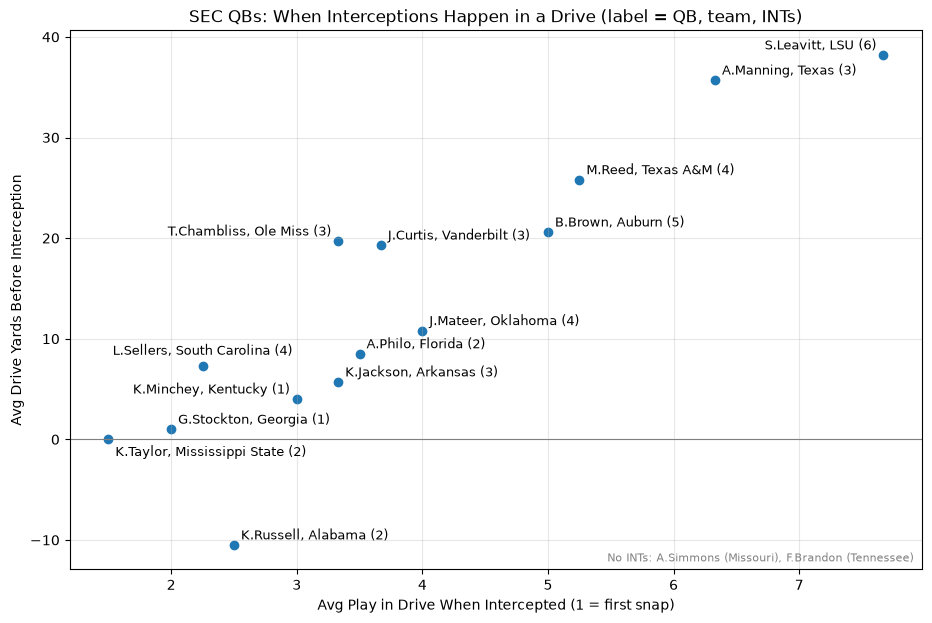

In [18]:
# QBs without an interception have no drive stats, so they can't be plotted
plot_df = qbs[qbs['interceptions'] > 0]
no_ints = qbs.loc[qbs['interceptions'] == 0, 'qb'] + ' (' + qbs.loc[qbs['interceptions'] == 0, 'team'] + ')'

fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(plot_df['avg_play_in_drive'], plot_df['avg_drive_yards_before_int'])

# label each dot: try the spots below in order and use the first that stays inside the plot
# and doesn't cover another label or dot
from matplotlib.transforms import Bbox
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
spots = [((5, 4), 'left'), ((5, -12), 'left'), ((-5, 4), 'right'), ((-5, -12), 'right'),
         ((0, 8), 'center'), ((0, -16), 'center'), ((5, 14), 'left'), ((5, -22), 'left')]
dot_px = ax.transData.transform(plot_df[['avg_play_in_drive', 'avg_drive_yards_before_int']].to_numpy())
plot_area = ax.get_window_extent(renderer)
placed = [Bbox.from_extents(px - 4, py - 4, px + 4, py + 4) for px, py in dot_px]   # the dots themselves
for _, row in plot_df.iterrows():
    label = f"{row['qb']}, {row['team']} ({row['interceptions']})"
    xy = (row['avg_play_in_drive'], row['avg_drive_yards_before_int'])
    for offset, ha in spots:
        ann = ax.annotate(label, xy, xytext=offset, textcoords='offset points', fontsize=9, ha=ha)
        box = ann.get_window_extent(renderer)
        inside = plot_area.x0 <= box.x0 and box.x1 <= plot_area.x1 and plot_area.y0 <= box.y0 and box.y1 <= plot_area.y1
        if inside and not any(box.overlaps(b) for b in placed):
            break
        ann.remove()
    else:   # every spot overlaps: fall back to the first one
        ann = ax.annotate(label, xy, xytext=spots[0][0], textcoords='offset points', fontsize=9)
        box = ann.get_window_extent(renderer)
    placed.append(box)

ax.axhline(0, color='gray', linewidth=0.8)
ax.set_xlabel('Avg Play in Drive When Intercepted (1 = first snap)')
ax.set_ylabel('Avg Drive Yards Before Interception')
ax.set_title('SEC QBs: When Interceptions Happen in a Drive (label = QB, team, INTs)')
if len(no_ints):
    ax.text(0.99, 0.01, 'No INTs: ' + ', '.join(no_ints), transform=ax.transAxes,
            ha='right', va='bottom', fontsize=8, color='gray')
ax.grid(alpha=0.3)
plt.show()

## Interceptions by QB

One dot per QB (all QBs who threw an interception, including backups), averaged over their interceptions,
from the second query in the same file.

In [19]:
# second query in the file: one row per interception
detail_query = "-- " + sql.split("-- ---------- 2.")[1]
detail_query = detail_query.replace("%", "%%")   # same % escaping as above

ints = pd.read_sql(detail_query, engine)
ints[['down', 'yards_to_go']] = ints['down_distance'].str.split(' & ', expand=True).astype(int)
ints

,team,week,opponent,passer,clock,down_distance,yards_to_goal,play_in_drive,passes_before,rushes_before,sacks_before,drive_yards_before,pick_six,qb_hurried,play_text,down,yards_to_go
0,Alabama,2,Kentucky,K.Russell,Q1 10:11,3 & 22,92,3,0,1,1,-12,True,False,(10:15) Shotgun #12 K.Russell pass intercepted...,3,22
1,Alabama,2,Kentucky,K.Russell,Q2 00:55,2 & 19,69,2,0,0,1,-9,False,False,(00:55) Shotgun #12 K.Russell pass intercepted...,2,19
2,Arkansas,1,North Alabama,K.Jackson,Q2 00:19,3 & 8,14,4,1,2,0,12,False,False,(00:23) No Huddle-Shotgun #7 K.Jackson pass in...,3,8
3,Arkansas,2,Utah,K.Jackson,Q2 10:59,1 & 25,73,3,1,1,0,3,False,False,(10:59) No Huddle #7 K.Jackson pass intercepte...,1,25
4,Arkansas,4,Tulsa,K.Jackson,Q3 05:50,3 & 8,49,3,0,2,0,2,False,True,(05:55) No Huddle-Shotgun #7 K.Jackson pass in...,3,8
5,Auburn,1,Baylor,B.Brown,Q2 07:20,2 & 7,48,7,3,3,0,45,False,False,(07:20) No Huddle-Shotgun #17 B.Brown pass int...,2,7
6,Auburn,1,Baylor,B.Brown,Q2 00:03,3 & 23,26,11,7,1,2,49,False,False,(00:13) No Huddle-Shotgun #17 B.Brown pass int...,3,23
7,Auburn,1,Baylor,B.Brown,Q4 11:46,1 & 10,62,1,0,0,0,0,False,False,(11:53) No Huddle-Shotgun #17 B.Brown pass int...,1,10
8,Auburn,3,Florida,B.Brown,Q1 14:12,3 & 3,68,3,1,1,0,7,False,False,(14:17) No Huddle-Shotgun #17 B.Brown pass int...,3,3
9,Auburn,4,Vanderbilt,B.Brown,Q1 11:28,3 & 8,84,3,1,1,0,2,False,False,(11:34) No Huddle-Shotgun #17 B.Brown pass int...,3,8


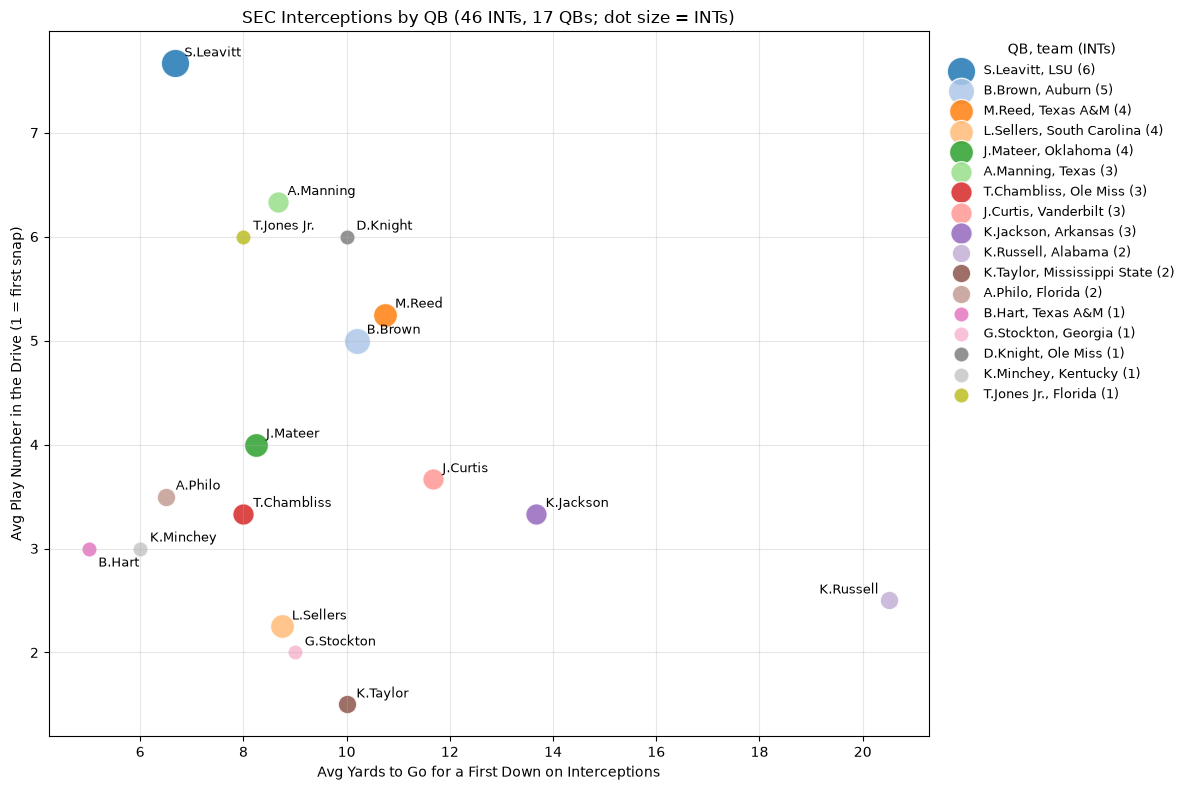

In [20]:
from matplotlib.transforms import Bbox

# one row per QB: averages over that QB's interceptions
by_qb = (ints.groupby(['passer', 'team'], as_index=False)
             .agg(interceptions=('passer', 'size'),
                  avg_yards_to_go=('yards_to_go', 'mean'),
                  avg_play_in_drive=('play_in_drive', 'mean'))
             .sort_values('interceptions', ascending=False)
             .reset_index(drop=True))

# a different color per QB (tab20 has 20 colors); past ~8 colors some look alike,
# so every dot is also labeled with the QB's name
colors = plt.get_cmap('tab20').colors

fig, ax = plt.subplots(figsize=(12, 8))
for i, row in by_qb.iterrows():
    ax.scatter(row['avg_yards_to_go'], row['avg_play_in_drive'],
               s=60 + 60 * row['interceptions'],          # bigger dot = more INTs
               color=colors[i % len(colors)], alpha=0.85, edgecolor='white', linewidth=1,
               label=f"{row['passer']}, {row['team']} ({row['interceptions']})")

# name labels: try spots around each dot and use the first that stays inside the plot
# and doesn't cover another label or dot
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
spots = [((7, 5), 'left'), ((7, -13), 'left'), ((-7, 5), 'right'), ((-7, -13), 'right'),
         ((0, 10), 'center'), ((0, -18), 'center'), ((7, 15), 'left'), ((7, -23), 'left')]
plot_area = ax.get_window_extent(renderer)
dot_px = ax.transData.transform(by_qb[['avg_yards_to_go', 'avg_play_in_drive']].to_numpy())
placed = [Bbox.from_extents(px - 6, py - 6, px + 6, py + 6) for px, py in dot_px]
for _, row in by_qb.iterrows():
    xy = (row['avg_yards_to_go'], row['avg_play_in_drive'])
    for offset, ha in spots:
        ann = ax.annotate(row['passer'], xy, xytext=offset, textcoords='offset points', fontsize=9, ha=ha)
        box = ann.get_window_extent(renderer)
        inside = (plot_area.x0 <= box.x0 and box.x1 <= plot_area.x1
                  and plot_area.y0 <= box.y0 and box.y1 <= plot_area.y1)
        if inside and not any(box.overlaps(b) for b in placed):
            break
        ann.remove()
    else:   # every spot is taken: fall back to the first one
        ann = ax.annotate(row['passer'], xy, xytext=spots[0][0], textcoords='offset points', fontsize=9)
        box = ann.get_window_extent(renderer)
    placed.append(box)

ax.set_xlabel('Avg Yards to Go for a First Down on Interceptions')
ax.set_ylabel('Avg Play Number in the Drive (1 = first snap)')
ax.set_title(f'SEC Interceptions by QB ({len(ints)} INTs, {len(by_qb)} QBs; dot size = INTs)')
ax.legend(title='QB, team (INTs)', loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False, fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## QB INT grades

Grades each team's main QB (most pass plays) on ball security, 0-100 (higher = better), relative to the other SEC starters.
Every part is per 100 pass plays so QBs with more throws aren't penalized just for volume.

| Part | Weight | What counts |
|---|---|---|
| INT rate | 50% | every interception |
| Costly INTs | 30% | pick-six, thrown in the red zone (inside the 20), or in the last 2:00 of a half |
| Unforced INTs | 20% | thrown on 1st or 2nd down, or on 3rd & 5 or shorter (not a must-throw situation) |

Each part is scaled between the best and worst starter (best = 100, worst = 0, linear in between), then weighted,
so a QB with no interceptions scores 100.
Letter grades: A >= 85, B >= 70, C >= 55, D >= 40, F < 40.
Each interception is put in one bucket for the breakdown chart: costly first, then unforced, otherwise forced
(3rd & 6+ or 4th down). Small samples: one interception moves a grade a lot this early in the season.

In [21]:
# classify every interception (from the second query) ...
d = ints.copy()
d['quarter'] = d['clock'].str.extract(r'Q(\d+)')[0].astype(int)
mm_ss = d['clock'].str.extract(r'(\d+):(\d+)').astype(int)
d['secs_left'] = mm_ss[0] * 60 + mm_ss[1]
d['costly'] = d['pick_six'] | (d['yards_to_goal'] <= 20) | (d['quarter'].isin([2, 4]) & (d['secs_left'] <= 120))
d['unforced'] = (d['down'] <= 2) | ((d['down'] == 3) & (d['yards_to_go'] <= 5))
d['bucket'] = np.where(d['costly'], 'Costly', np.where(d['unforced'], 'Unforced', 'Forced'))

# ... and count them for each team's main QB (first query: one QB per team, incl. QBs with 0 INTs)
counts = (d.groupby(['team', 'passer'])
           .agg(costly=('costly', 'sum'), unforced=('unforced', 'sum'),
                b_costly=('bucket', lambda b: (b == 'Costly').sum()),
                b_unforced=('bucket', lambda b: (b == 'Unforced').sum()),
                b_forced=('bucket', lambda b: (b == 'Forced').sum()))
           .reset_index().rename(columns={'passer': 'qb'}))
grades = (qbs[['team', 'qb', 'pass_plays', 'interceptions', 'ints_per_100_passes']]
          .merge(counts, on=['team', 'qb'], how='left').fillna(0))

grades['costly_per_100'] = 100 * grades['costly'] / grades['pass_plays']
grades['unforced_per_100'] = 100 * grades['unforced'] / grades['pass_plays']


def scale_score(values):
    """best (lowest) value = 100, worst (highest) = 0, linear in between"""
    lo, hi = values.min(), values.max()
    return 100 * (hi - values) / (hi - lo) if hi > lo else values * 0 + 100


grades['rate_score'] = scale_score(grades['ints_per_100_passes'])
grades['costly_score'] = scale_score(grades['costly_per_100'])
grades['unforced_score'] = scale_score(grades['unforced_per_100'])
grades['grade_score'] = (0.5 * grades['rate_score'] + 0.3 * grades['costly_score']
                         + 0.2 * grades['unforced_score']).round(1)
grades['grade'] = pd.cut(grades['grade_score'], [-1, 40, 55, 70, 85, 101],
                         labels=['F', 'D', 'C', 'B', 'A'], right=False).astype(str)
grades = grades.sort_values('grade_score', ascending=False).reset_index(drop=True)
grades[['team', 'qb', 'grade', 'grade_score', 'pass_plays', 'interceptions', 'ints_per_100_passes',
        'costly', 'unforced', 'rate_score', 'costly_score', 'unforced_score']]

,team,qb,grade,grade_score,pass_plays,interceptions,ints_per_100_passes,costly,unforced,rate_score,costly_score,unforced_score
0,Tennessee,F.Brandon,A,100.0,96,0,0.00,0.0,0.0,100.000000,100.000000,100.000000
1,Missouri,A.Simmons,A,100.0,107,0,0.00,0.0,0.0,100.000000,100.000000,100.000000
2,Kentucky,K.Minchey,B,79.1,101,1,0.99,1.0,0.0,81.034483,62.046205,100.000000
3,Ole Miss,T.Chambliss,B,74.8,144,3,2.08,0.0,1.0,60.153257,100.000000,73.379630
4,Georgia,G.Stockton,B,74.3,67,1,1.49,0.0,1.0,71.455939,100.000000,42.786070
5,Mississippi State,K.Taylor,B,71.2,120,2,1.67,0.0,2.0,68.007663,100.000000,36.111111
6,Oklahoma,J.Mateer,C,64.8,109,4,3.67,0.0,0.0,29.693487,100.000000,100.000000
7,Florida,A.Philo,C,64.8,87,2,2.30,1.0,0.0,55.938697,55.938697,100.000000
8,Arkansas,K.Jackson,C,64.5,135,3,2.22,1.0,1.0,57.471264,71.604938,71.604938
9,Alabama,K.Russell,D,54.7,110,2,1.82,2.0,1.0,65.134100,30.303030,65.151515


In [22]:
# shared chart style
INK, SECONDARY, MUTED, GRID = '#0b0b0b', '#52514e', '#898781', '#e1e0d9'


def clean_axes(ax, grid_axis='x'):
    for side in ['top', 'right', 'left']:
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color('#c3c2b7')
    ax.tick_params(axis='y', length=0)
    ax.tick_params(axis='x', colors=MUTED, labelsize=9)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


def qb_label(r):
    return f"{r['qb']} ({r['team']})"

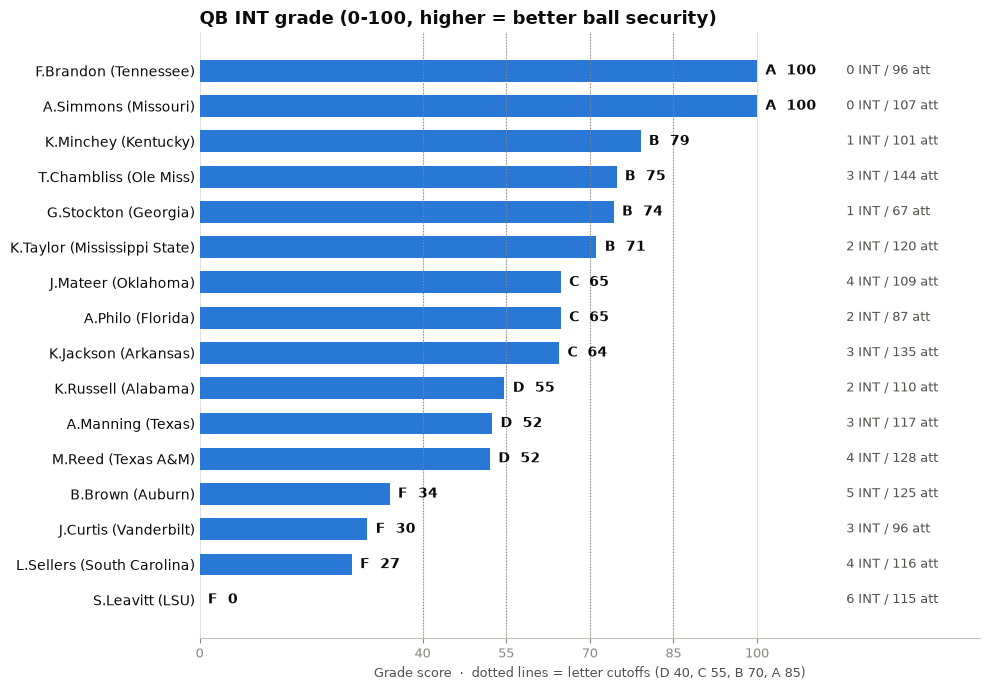

In [23]:
# Chart 1: report card
g = grades.iloc[::-1]                     # best grade at the top
y = np.arange(len(g))

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(y, g['grade_score'], height=0.62, color='#2a78d6')
for yi, (_, r) in zip(y, g.iterrows()):
    ax.text(r['grade_score'] + 1.5, yi, f"{r['grade']}  {r['grade_score']:.0f}",
            va='center', fontsize=10, color=INK, fontweight='bold')
    ax.text(116, yi, f"{int(r['interceptions'])} INT / {int(r['pass_plays'])} att",
            va='center', fontsize=9, color=SECONDARY)

ax.set_yticks(y)
ax.set_yticklabels([qb_label(r) for _, r in g.iterrows()], fontsize=10, color=INK)
ax.set_xlim(0, 140)
ax.set_xticks([0, 40, 55, 70, 85, 100])
for cut in [40, 55, 70, 85]:
    ax.axvline(cut, color=MUTED, linestyle=':', linewidth=0.8)
clean_axes(ax)
ax.set_title('QB INT grade (0-100, higher = better ball security)', loc='left',
             fontsize=13, fontweight='bold', color=INK)
ax.set_xlabel('Grade score  ·  dotted lines = letter cutoffs (D 40, C 55, B 70, A 85)',
              color=SECONDARY, fontsize=9)
plt.tight_layout()
plt.show()

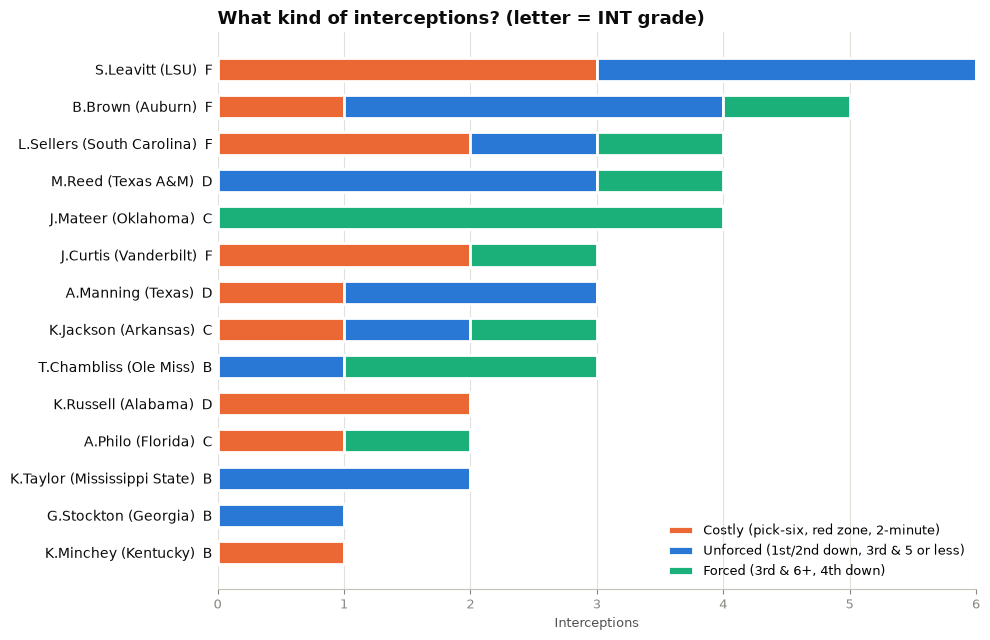

In [24]:
# Chart 2: what kind of interceptions each QB throws (only QBs with at least one)
b = grades[grades['interceptions'] > 0].sort_values(['interceptions', 'grade_score'], ascending=[True, False])
y = np.arange(len(b))
buckets = [('b_costly', 'Costly (pick-six, red zone, 2-minute)', '#eb6834'),
           ('b_unforced', 'Unforced (1st/2nd down, 3rd & 5 or less)', '#2a78d6'),
           ('b_forced', 'Forced (3rd & 6+, 4th down)', '#1baf7a')]

fig, ax = plt.subplots(figsize=(10, 6.5))
left = np.zeros(len(b))
for col, name, color in buckets:
    ax.barh(y, b[col], left=left, height=0.62, color=color, edgecolor='white', linewidth=2, label=name)
    left += b[col].to_numpy()

ax.set_yticks(y)
ax.set_yticklabels([f"{qb_label(r)}  {r['grade']}" for _, r in b.iterrows()], fontsize=10, color=INK)
ax.xaxis.get_major_locator().set_params(integer=True)
clean_axes(ax)
ax.set_title('What kind of interceptions? (letter = INT grade)', loc='left',
             fontsize=13, fontweight='bold', color=INK)
ax.set_xlabel('Interceptions', color=SECONDARY, fontsize=9)
ax.legend(loc='lower right', frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

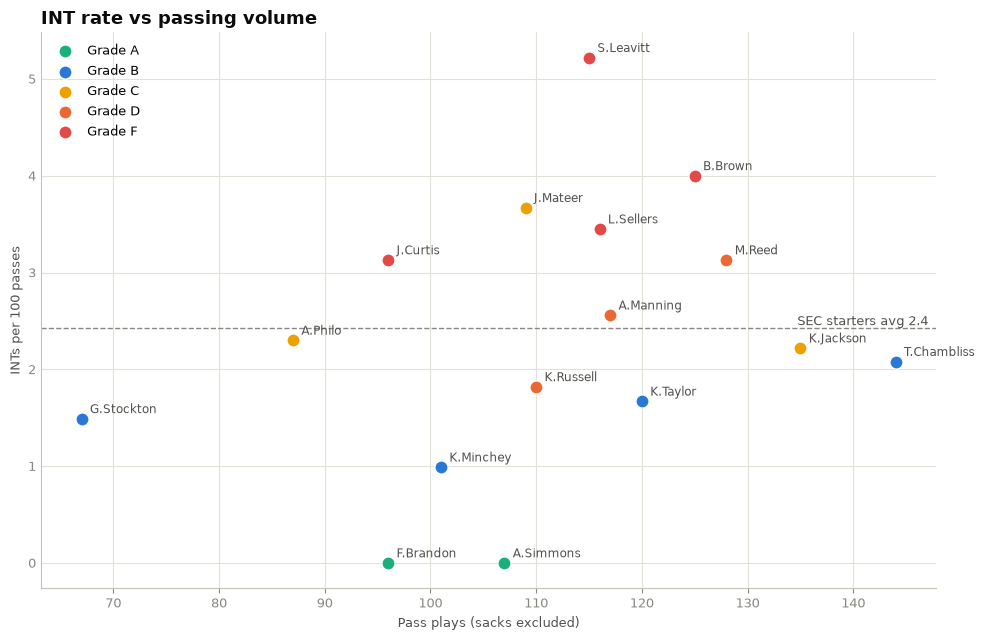

In [25]:
# Chart 3: INT rate vs passing volume (a high rate on few throws is less certain)
grade_colors = {'A': '#1baf7a', 'B': '#2a78d6', 'C': '#eda100', 'D': '#eb6834', 'F': '#e34948'}
sec_rate = 100 * grades['interceptions'].sum() / grades['pass_plays'].sum()

fig, ax = plt.subplots(figsize=(10, 6.5))
for grade, color in grade_colors.items():
    m = grades['grade'] == grade
    if m.any():
        ax.scatter(grades.loc[m, 'pass_plays'], grades.loc[m, 'ints_per_100_passes'], s=90,
                   color=color, edgecolor='white', linewidth=1, label=f'Grade {grade}', zorder=3)
for _, r in grades.iterrows():
    ax.annotate(r['qb'], (r['pass_plays'], r['ints_per_100_passes']), xytext=(6, 4),
                textcoords='offset points', fontsize=8.5, color=SECONDARY)

ax.axhline(sec_rate, color=MUTED, linestyle='--', linewidth=1)
ax.text(ax.get_xlim()[1], sec_rate, f'SEC starters avg {sec_rate:.1f}  ', ha='right', va='bottom',
        fontsize=9, color=SECONDARY)
clean_axes(ax, grid_axis='both')
ax.spines['left'].set_visible(True)
ax.spines['left'].set_color('#c3c2b7')
ax.tick_params(axis='y', colors=MUTED, labelsize=9)
ax.set_xlabel('Pass plays (sacks excluded)', color=SECONDARY, fontsize=9)
ax.set_ylabel('INTs per 100 passes', color=SECONDARY, fontsize=9)
ax.set_title('INT rate vs passing volume', loc='left', fontsize=13, fontweight='bold', color=INK)
ax.legend(frameon=False, fontsize=9, loc='upper left')
plt.tight_layout()
plt.show()